# 03 · VAR model & Granger causality
**Question:** do wind speed and humidity *Granger-cause* PM2.5? In other words, does knowing past weather
improve the prediction of PM2.5 beyond what PM2.5's own past gives?

**Setup**
* Daily data, **2015-01-01 → 2019-12-31**. The 2020 COVID lockdown is left out because it is an
  emissions shock, not a weather effect.
* System: `wind`, `rh` and `pm25` (log). All three are **deseasonalised first**.
* Why deseasonalise? Wind, humidity and PM2.5 all follow the same calendar. Without removing that, Granger
  would mostly detect "it's winter" instead of a real lead-lag effect.
* Method: subtract each variable's smoothed day-of-year climatology (31-day circular window).
* Robustness check: repeat the analysis using plain first differences.

In [1]:
import sys
sys.path.append("..")

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.api import VAR

from src.data import PROCESSED, RESULTS
from src.tsa import doy_climatology, doy_anomaly, stationarity_table, pairwise_granger
from src.plots import use_style, savefig, VAR_COLORS, BLUE, ORANGE, AQUA, INK, INK_2, MUTED, NEUTRAL, SURFACE

warnings.filterwarnings("ignore", category=FutureWarning)
use_style()
daily = pd.read_csv(PROCESSED / "delhi_daily.csv", index_col="Date", parse_dates=True).asfreq("D")
d = daily.loc[:"2019-12-31"]
key = {"var_sample": f"{d.index.min().date()} to {d.index.max().date()} ({len(d)} days)"}
NAMES = {"wind": "Wind", "rh": "Humidity", "pm25": "PM2.5"}

## 1. Remove the seasonal cycle

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


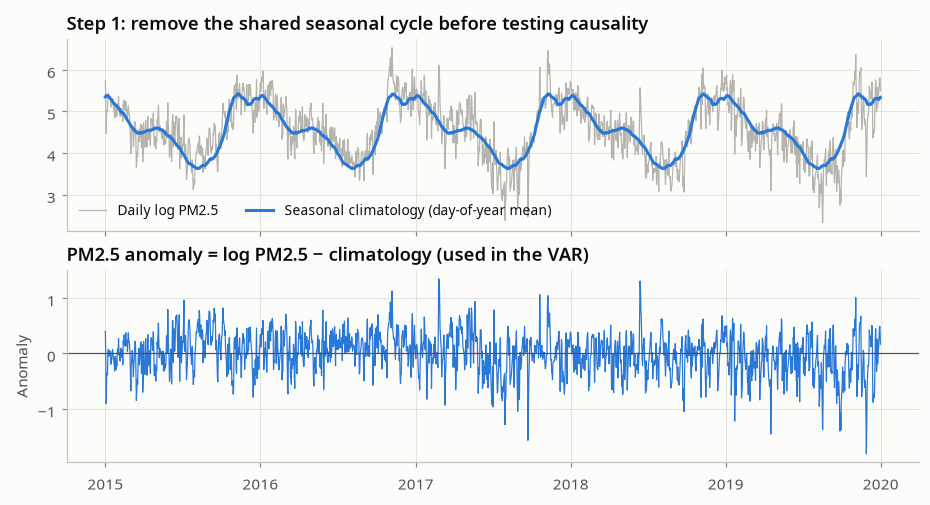

In [2]:
anom = pd.DataFrame({
    "wind": doy_anomaly(d["wind"]),
    "rh": doy_anomaly(d["rh"]),
    "pm25": doy_anomaly(d["log_pm25"]),
})
assert anom.notna().all().all()

clim = doy_climatology(d["log_pm25"])
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(d.index, d["log_pm25"], color=NEUTRAL, lw=0.8, label="Daily log PM2.5")
axes[0].plot(d.index, clim.reindex(np.minimum(d.index.dayofyear, 365)).to_numpy(), color=BLUE, lw=2,
             label="Seasonal climatology (day-of-year mean)")
axes[0].set_title("Step 1: remove the shared seasonal cycle before testing causality")
axes[0].legend(loc="lower left", ncols=2)
axes[1].plot(anom.index, anom["pm25"], color=BLUE, lw=0.8)
axes[1].axhline(0, color=INK_2, lw=0.8)
axes[1].set_ylabel("Anomaly")
axes[1].set_title("PM2.5 anomaly = log PM2.5 − climatology (used in the VAR)")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
savefig(fig, "07_deseasonalise")
plt.show()

In [3]:
anom_stationarity = stationarity_table({f"{NAMES[c]} anomaly": anom[c] for c in anom})
anom_stationarity.to_csv(RESULTS / "stationarity_anomalies.csv")
anom_stationarity

,n,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict
series,,,,,,,
Wind anomaly,1826,-19.569,0.0,3,1.050,0.01,"Mixed (ADF says stationary, KPSS rejects)"
Humidity anomaly,1826,-12.605,0.0,3,0.225,0.10,Stationary
PM2.5 anomaly,1826,-6.601,0.0,18,2.033,0.01,"Mixed (ADF says stationary, KPSS rejects)"


ADF strongly rejects a unit root for all three anomaly series (statistics far below the 1% critical value
of about −3.4). KPSS still flags wind and PM2.5, because with n ≈ 1,800 it reacts to small slow drifts
(e.g. the PM2.5 decline in 2019). We therefore fit the VAR on the anomalies, and in Section 6 we re-run
everything on **first differences**, which pass both tests, to check the conclusion is the same.

## 2. Lag-order selection

In [4]:
model = VAR(anom)
order = model.select_order(maxlags=14)
lag_table = pd.DataFrame({ic: [getattr(order, "ics")[ic][p] for p in range(15)] for ic in ["aic", "bic", "hqic", "fpe"]})
lag_table.index.name = "lag"
lag_table.round(4).to_csv(RESULTS / "var_lag_selection.csv")
print("Selected orders:", {k: int(v) for k, v in order.selected_orders.items()})
lag_table.style.highlight_min(axis=0, props="font-weight:bold; background-color:#cde2fb")

Selected orders: {'aic': 4, 'bic': 2, 'hqic': 3, 'fpe': 4}


,aic,bic,hqic,fpe
lag,,,,
0,4.477290,4.486400,4.480652,87.995884
1,2.564363,2.600801,2.577809,12.992377
2,2.442175,2.505942,2.465706,11.498017
3,2.431821,2.522916,2.465436,11.379586
4,2.425956,2.544380,2.469656,11.313047
5,2.431830,2.577583,2.485615,11.379702
6,2.430455,2.603537,2.494325,11.364078
7,2.435935,2.636346,2.509890,11.426539
8,2.433846,2.661585,2.517885,11.402710


In [5]:
p = int(order.selected_orders["aic"])
res = model.fit(p)
whiteness = res.test_whiteness(nlags=p + 10)
key.update({
    "var_lag_aic": p, "var_lag_bic": int(order.selected_orders["bic"]),
    "var_stable": bool(res.is_stable()),
    "portmanteau_p": round(float(whiteness.pvalue), 3),
})
print(f"VAR({p}) — stable: {res.is_stable()} | Portmanteau test (H0: residuals white, {p + 10} lags): p = {whiteness.pvalue:.3f}")

VAR(4) — stable: True | Portmanteau test (H0: residuals white, 14 lags): p = 0.173


AIC picks **p = 4 days**, BIC picks 2 and HQIC picks 3. We use the AIC lag, and Section 6 checks the
result under the BIC lag too. The fitted VAR is **stable** and its residuals pass the multivariate
Portmanteau test (no autocorrelation left), so the model is adequate for inference.

### Stability: companion-matrix eigenvalues must lie inside the unit circle

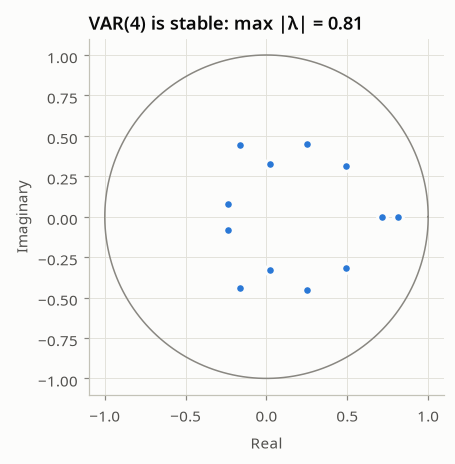

In [6]:
eig = 1 / res.roots
fig, ax = plt.subplots(figsize=(4.2, 4.2))
theta = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), color=MUTED, lw=1)
ax.scatter(eig.real, eig.imag, s=40, color=BLUE, edgecolors=SURFACE, linewidths=2, zorder=3)
ax.set_aspect("equal")
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_title(f"VAR({p}) is stable: max |λ| = {np.abs(eig).max():.2f}")
ax.set_xlabel("Real")
ax.set_ylabel("Imaginary")
savefig(fig, "08_var_stability")
plt.show()
key["max_eigen_modulus"] = round(float(np.abs(eig).max()), 3)

## 3. Granger causality tests (from the fitted VAR)
H0: all lagged coefficients of the *causing* variable in the *caused* variable's equation are zero.

In [7]:
def granger_rows(results, label):
    rows = []
    for causing, caused in [("wind", "pm25"), ("rh", "pm25"), (["wind", "rh"], "pm25"), ("pm25", "wind"), ("pm25", "rh")]:
        t = results.test_causality(caused, causing, kind="f")
        name = " + ".join(NAMES[c] for c in np.atleast_1d(causing))
        rows.append({
            "spec": label, "direction": f"{name} → {NAMES[caused]}",
            "F": round(t.test_statistic, 2), "df": f"({t.df[0]}, {t.df[1]})", "p_value": t.pvalue,
            "verdict (5%)": "Granger-causes" if t.pvalue < 0.05 else "No evidence",
        })
    return rows

granger = pd.DataFrame(granger_rows(res, f"Anomalies, VAR({p})"))
granger.to_csv(RESULTS / "granger_var.csv", index=False)
granger.style.format({"p_value": "{:.2e}"})

,spec,direction,F,df,p_value,verdict (5%)
0,"Anomalies, VAR(4)",Wind → PM2.5,35.700000,"(4, 5427)",1.73e-29,Granger-causes
1,"Anomalies, VAR(4)",Humidity → PM2.5,14.380000,"(4, 5427)",1.11e-11,Granger-causes
2,"Anomalies, VAR(4)",Wind + Humidity → PM2.5,21.890000,"(8, 5427)",3.98e-33,Granger-causes
3,"Anomalies, VAR(4)",PM2.5 → Wind,1.800000,"(4, 5427)",1.27e-01,No evidence
4,"Anomalies, VAR(4)",PM2.5 → Humidity,0.670000,"(4, 5427)",6.15e-01,No evidence


**Result:** the direction is one-way. Weather → PM2.5 is highly significant (p ≪ 0.001).
PM2.5 → weather, the reverse direction, is **not** significant. That is the physically expected pattern:
pollution does not change the next day's wind, but wind does disperse pollution.

### Pairwise Granger tests across lags 1–7 days

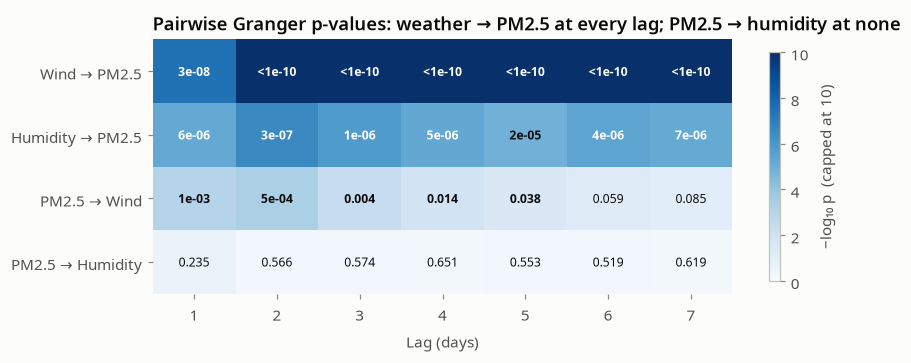

In [8]:
pairs = [("wind", "pm25"), ("rh", "pm25"), ("pm25", "wind"), ("pm25", "rh")]
pw = pairwise_granger(anom, pairs, maxlag=7)
pw.index = [f"{NAMES[a]} → {NAMES[b]}" for a, b in pairs]
pw.to_csv(RESULTS / "granger_pairwise_lags.csv")

score = -np.log10(pw.clip(lower=1e-30))
fig, ax = plt.subplots(figsize=(8.5, 3))
im = ax.imshow(score.clip(upper=10), cmap="Blues", vmin=0, vmax=10, aspect="auto")
ax.set_xticks(range(7), [str(c) for c in pw.columns])
ax.set_yticks(range(len(pw)), pw.index)
ax.set_xlabel("Lag (days)")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(pw.shape[0]):
    for j in range(pw.shape[1]):
        v = pw.iloc[i, j]
        txt = "<1e-10" if v < 1e-10 else (f"{v:.0e}" if v < 0.001 else f"{v:.3f}")
        ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                color="white" if score.iloc[i, j] > 5 else INK, fontweight="bold" if v < 0.05 else "normal")
fig.colorbar(im, ax=ax, label="−log₁₀ p  (capped at 10)", shrink=0.9)
ax.set_title("Pairwise Granger p-values: weather → PM2.5 at every lag; PM2.5 → humidity at none")
savefig(fig, "09_granger_pvalues")
plt.show()

Bold means p < 0.05. In pairwise tests, PM2.5 → wind is weakly significant at short lags. Once humidity is
also in the model (the full VAR above), that disappears (p ≈ 0.13), so it is not robust.

## 4. Impulse responses: how much does PM2.5 respond to a weather shock?
These are orthogonalised (Cholesky) IRFs with ordering wind → humidity → PM2.5, so weather is allowed to
affect PM2.5 on the same day. The response of log PM2.5 is converted to a **% change**.

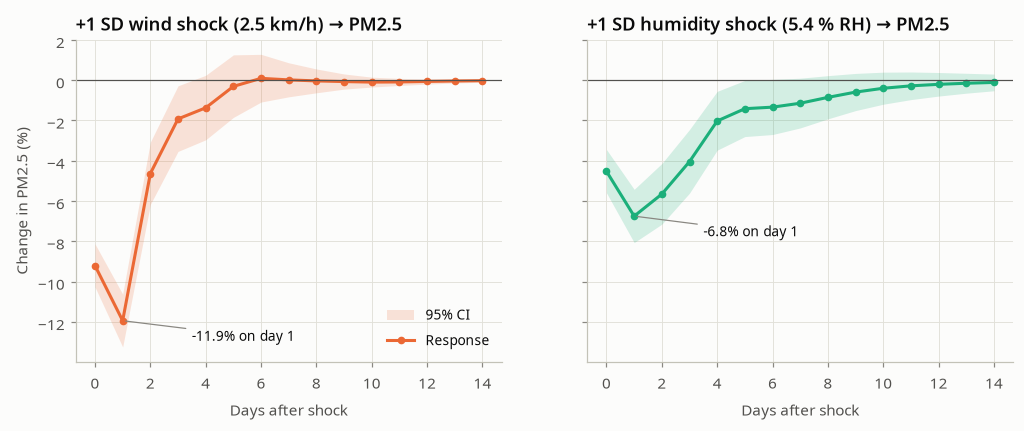

{'wind': {'peak_pct': -11.9, 'peak_day': 1, 'shock_sd': 2.54, 'unit': 'km/h'},
 'rh': {'peak_pct': -6.8, 'peak_day': 1, 'shock_sd': 5.43, 'unit': '% RH'}}

In [9]:
H = 14
irf = res.irf(H)
idx = {c: i for i, c in enumerate(anom.columns)}
se = irf.stderr(orth=True)
shock_sd = np.sqrt(np.diag(res.sigma_u))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
irf_summary = {}
for ax, imp in zip(axes, ["wind", "rh"]):
    r = irf.orth_irfs[:, idx["pm25"], idx[imp]]
    s = se[:, idx["pm25"], idx[imp]]
    pct, lo, hi = [(np.exp(x) - 1) * 100 for x in (r, r - 1.96 * s, r + 1.96 * s)]
    h = np.arange(H + 1)
    c = VAR_COLORS[imp]
    ax.fill_between(h, lo, hi, color=c, alpha=0.18, lw=0, label="95% CI")
    ax.plot(h, pct, color=c, lw=2, marker="o", markersize=4, label="Response")
    ax.axhline(0, color=INK_2, lw=0.8)
    k = int(np.argmin(pct))
    ax.annotate(f"{pct[k]:.1f}% on day {k}", xy=(k, pct[k]), xytext=(k + 2.5, pct[k] - 1),
                fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    unit = "km/h" if imp == "wind" else "% RH"
    ax.set_title(f"+1 SD {NAMES[imp].lower()} shock ({shock_sd[idx[imp]]:.1f} {unit}) → PM2.5")
    ax.set_xlabel("Days after shock")
    irf_summary[imp] = {"peak_pct": round(float(pct[k]), 1), "peak_day": k,
                        "shock_sd": round(float(shock_sd[idx[imp]]), 2), "unit": unit}
axes[0].set_ylabel("Change in PM2.5 (%)")
axes[0].legend(loc="lower right")
savefig(fig, "10_irf_weather_to_pm25")
plt.show()
key["irf"] = irf_summary
irf_summary

## 5. Forecast-error variance decomposition of PM2.5
How much of the uncertainty in future PM2.5 comes from each variable's shocks?

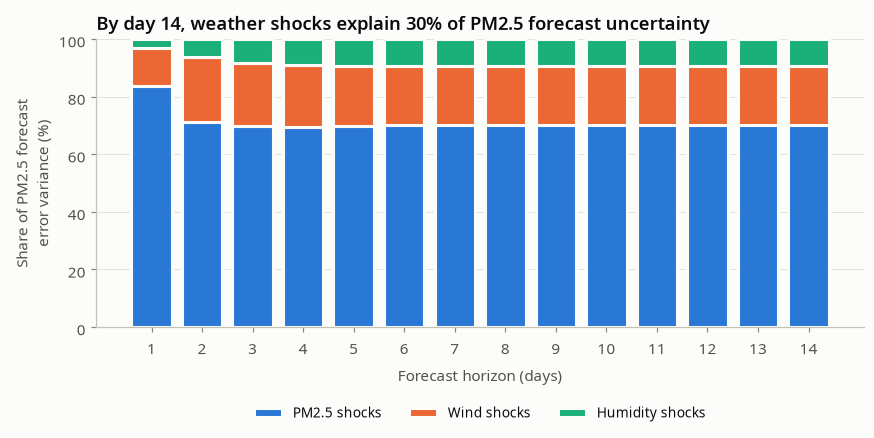

,Wind,Humidity,PM2.5
horizon (days),,,
1,13.2,3.0,83.7
3,22.1,8.3,69.6
7,20.6,9.4,70.1
14,20.4,9.5,70.1


In [10]:
fevd = pd.DataFrame(res.fevd(H).decomp[idx["pm25"]] * 100, columns=[NAMES[c] for c in anom.columns],
                    index=pd.RangeIndex(1, H + 1, name="horizon (days)"))
fevd.round(1).to_csv(RESULTS / "fevd_pm25.csv")

fig, ax = plt.subplots(figsize=(9, 3.4))
bottom = np.zeros(H)
for col, var in [("PM2.5", "pm25"), ("Wind", "wind"), ("Humidity", "rh")]:
    ax.bar(fevd.index, fevd[col], bottom=bottom, color=VAR_COLORS[var], edgecolor=SURFACE, linewidth=2,
           width=0.8, label=f"{col} shocks")
    bottom += fevd[col].to_numpy()
ax.set_ylim(0, 100)
ax.set_xlabel("Forecast horizon (days)")
ax.set_ylabel("Share of PM2.5 forecast\nerror variance (%)")
ax.set_xticks(fevd.index)
weather_share = fevd.loc[H, "Wind"] + fevd.loc[H, "Humidity"]
ax.set_title(f"By day {H}, weather shocks explain {weather_share:.0f}% of PM2.5 forecast uncertainty")
ax.legend(loc="upper center", ncols=3, bbox_to_anchor=(0.5, -0.22))
savefig(fig, "11_fevd_pm25")
plt.show()
key["fevd_weather_share_h14"] = round(float(weather_share), 1)
key["fevd_wind_h14"] = round(float(fevd.loc[H, "Wind"]), 1)
key["fevd_rh_h14"] = round(float(fevd.loc[H, "Humidity"]), 1)
fevd.loc[[1, 3, 7, 14]].round(1)

## 6. Robustness checks
1. Same anomalies, with the **BIC** lag.
2. **First differences** instead of anomalies. These pass both ADF and KPSS (notebook 02), with the lag
   chosen by AIC.

In [11]:
res_bic = model.fit(int(order.selected_orders["bic"]))
diffs = pd.DataFrame({"wind": d["wind"].diff(), "rh": d["rh"].diff(), "pm25": d["log_pm25"].diff()}).dropna()
model_d = VAR(diffs)
p_d = int(model_d.select_order(maxlags=14).selected_orders["aic"])
res_d = model_d.fit(p_d)

robust = pd.DataFrame(
    granger_rows(res, f"Anomalies, VAR({p}) [AIC]")
    + granger_rows(res_bic, f"Anomalies, VAR({res_bic.k_ar}) [BIC]")
    + granger_rows(res_d, f"First differences, VAR({p_d}) [AIC]")
)
robust.to_csv(RESULTS / "granger_robustness.csv", index=False)
robust.pivot(index="direction", columns="spec", values="p_value").map(lambda v: f"{v:.1e}")

spec,"Anomalies, VAR(2) [BIC]","Anomalies, VAR(4) [AIC]","First differences, VAR(14) [AIC]"
direction,,,
Humidity → PM2.5,4.6e-13,1.1e-11,1.5e-10
PM2.5 → Humidity,5.9e-01,6.1e-01,2.8e-01
PM2.5 → Wind,1.7e-02,1.3e-01,5.7e-01
Wind + Humidity → PM2.5,6.1e-37,4.0e-33,1.0e-27
Wind → PM2.5,5.8e-32,1.7e-29,7.8e-25


**Weather → PM2.5 is significant in every specification.** PM2.5 → humidity is never significant.
PM2.5 → wind is borderline only with the shortest (BIC) lag and vanishes otherwise.

## Conclusions for the presentation
* **Wind and humidity Granger-cause PM2.5** (p < 10⁻¹⁰). The finding holds across lag choices and
  deseasonalising methods. The reverse direction is not robustly significant.
* **Size of the effect:** a 1-SD gust anomaly (≈2.5 km/h) cuts PM2.5 by ≈12% the next day, fading within
  about 4 days. A 1-SD humidity anomaly (≈5% RH, usually rain) cuts PM2.5 by ≈7% and lasts about a week.
* **Weather explains about 30%** of PM2.5 forecast-error variance at a 2-week horizon. This justifies using
  wind and humidity as **exogenous regressors in SARIMAX** (Phase 4).
* **Caveat:** Granger causality is *predictive* causality. Unmeasured drivers such as mixing-layer height,
  stubble burning and festival fireworks could still confound the result.

In [12]:
key["granger"] = {r["direction"]: float(f"{r['p_value']:.3g}") for r in granger.to_dict("records")}
(RESULTS / "key_numbers_var.json").write_text(json.dumps(key, indent=2, ensure_ascii=False))
key

{'var_sample': '2015-01-01 to 2019-12-31 (1826 days)',
 'var_lag_aic': 4,
 'var_lag_bic': 2,
 'var_stable': True,
 'portmanteau_p': 0.173,
 'max_eigen_modulus': 0.811,
 'irf': {'wind': {'peak_pct': -11.9,
   'peak_day': 1,
   'shock_sd': 2.54,
   'unit': 'km/h'},
  'rh': {'peak_pct': -6.8, 'peak_day': 1, 'shock_sd': 5.43, 'unit': '% RH'}},
 'fevd_weather_share_h14': 29.9,
 'fevd_wind_h14': 20.4,
 'fevd_rh_h14': 9.5,
 'granger': {'Wind → PM2.5': 1.73e-29,
  'Humidity → PM2.5': 1.11e-11,
  'Wind + Humidity → PM2.5': 3.98e-33,
  'PM2.5 → Wind': 0.127,
  'PM2.5 → Humidity': 0.615}}